# 05 — Análise auxiliar das features robustas vs. `target_dias_atraso`

Diagnóstico das **22 features robustas dos notebooks 03B/04**. O notebook mede Pearson, Spearman e informação mútua, avalia estabilidade em horizontes de 180/90/60/30 dias, redundância entre features e as duas variáveis categóricas.

A análise principal usa apenas desenvolvimento e uma observação por contrato. O teste final não deve orientar a seleção de variáveis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
RANDOM_STATE = 42

paths = [
    Path("C:\\Users\\Gabriel\\OneDrive\\Documentos\\projeto_previsao_termino_obras\\data\\processed\\dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("modelagem_outputs/processed/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("dataset_modelagem_obras_snapshots_enriquecido.csv"),
]
DATASET_PATH = next((p for p in paths if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Ajuste DATASET_PATH para dataset_modelagem_obras_snapshots_enriquecido.csv")
print("Dataset:", DATASET_PATH)

Dataset: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots_enriquecido.csv


In [2]:
NUMERIC_FEATURES = ['prazo_original_dias', 'log_valor_total_contrato', 'perc_desconto_modelo', 'dias_assinatura_ate_os', 'fornecedor_contratos_anteriores', 'predio_contratos_anteriores', 'dias_desde_os', 'dias_restantes_prazo_vigente', 'pct_prazo_consumido', 'qtd_aditivos_prazo', 'pct_dias_aditados_sobre_prazo_original', 'qtd_aditivos_valor', 'pct_parcelas_concluidas_vs_previstas', 'atraso_medio_parcelas_dias', 'pct_parcelas_atrasadas', 'dias_desde_ultima_parcela_concluida', 'pct_financeiro_liberado', 'atraso_medio_liberacao_dias', 'gap_prazo_execucao', 'gap_prazo_financeiro']
CATEGORICAL_FEATURES = ['classificacao_contrato', 'id_setor_divisao']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "target_dias_atraso"

df = pd.read_csv(DATASET_PATH, low_memory=False, encoding="utf-8-sig")
for c in ["data_corte","data_conclusao_definitiva"]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

required = ["id_contrato", TARGET, "dias_restantes_prazo_vigente"] + FEATURES
missing = [c for c in required if c not in df.columns]
assert not missing, f"Colunas ausentes: {missing}"
assert len(FEATURES) == 22

print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())
print("Features:", len(FEATURES))

Shape: (633, 109)
Contratos: 48
Features: 22


## Base de desenvolvimento
Exclui o teste final e mantém snapshots aptos à regressão quando essas marcações existem.

In [3]:
base = df.copy()
if "flag_apto_treino" in base.columns:
    base = base[base["flag_apto_treino"].eq(1)].copy()
if "split_contrato_temporal" in base.columns:
    base = base[~base["split_contrato_temporal"].astype(str).str.lower().eq("test")].copy()
base = base[base[TARGET].notna()].copy()

print("Snapshots:", len(base))
print("Contratos:", base["id_contrato"].nunique())
print(base[TARGET].describe())

Snapshots: 436
Contratos: 40
count    436.000000
mean      57.509174
std       98.447056
min        0.000000
25%        0.000000
50%       12.000000
75%       75.000000
max      380.000000
Name: target_dias_atraso, dtype: float64


In [4]:
def snapshot_horizonte(data, h):
    # Informação disponível pelo menos h dias antes do prazo.
    x = data[data["dias_restantes_prazo_vigente"].ge(h)].copy()
    if x.empty:
        return x
    x["dist_horizonte"] = x["dias_restantes_prazo_vigente"] - h
    return (x.sort_values(["id_contrato","dist_horizonte","data_corte"])
             .groupby("id_contrato", as_index=False).first())

def corr_num(data):
    rows=[]
    for f in NUMERIC_FEATURES:
        z=data[[f,TARGET]].dropna()
        if len(z)<5 or z[f].nunique()<=1:
            p=s=np.nan
        else:
            p=z[f].corr(z[TARGET], method="pearson")
            s=z[f].corr(z[TARGET], method="spearman")
        rows.append({"feature":f,"n":len(z),"pearson":p,"spearman":s,
                     "abs_pearson":abs(p) if pd.notna(p) else np.nan,
                     "abs_spearman":abs(s) if pd.notna(s) else np.nan,
                     "pct_missing":data[f].isna().mean()})
    return pd.DataFrame(rows)

def mi_num(data):
    X=data[NUMERIC_FEATURES].copy()
    keep=[c for c in X if X[c].notna().any() and X[c].nunique(dropna=True)>1]
    X=X[keep].fillna(X[keep].median())
    if len(X)<5:
        return pd.DataFrame(columns=["feature","mutual_information"])
    mi=mutual_info_regression(X, data[TARGET].astype(float), random_state=RANDOM_STATE)
    return pd.DataFrame({"feature":keep,"mutual_information":mi})

## Correlação principal — horizonte de 90 dias
Seleciona no máximo um snapshot por contrato e nunca usa snapshot posterior ao horizonte.

Contratos cobertos: 33


,feature,n,pearson,spearman,abs_pearson,abs_spearman,pct_missing,mutual_information
15,dias_desde_ultima_parcela_concluida,21,-0.2739,-0.5333,0.2739,0.5333,0.3636,0.0007
17,atraso_medio_liberacao_dias,19,-0.2382,-0.2832,0.2382,0.2832,0.4242,0.0502
2,perc_desconto_modelo,10,0.3175,0.2390,0.3175,0.2390,0.6970,0.0826
11,qtd_aditivos_valor,33,-0.0164,0.1912,0.0164,0.1912,0.0000,0.0000
16,pct_financeiro_liberado,33,0.3032,0.1678,0.3032,0.1678,0.0000,0.0000
10,pct_dias_aditados_sobre_prazo_original,33,0.0689,0.1533,0.0689,0.1533,0.0000,0.0000
9,qtd_aditivos_prazo,33,0.0890,0.1442,0.0890,0.1442,0.0000,0.0000
0,prazo_original_dias,33,0.1999,0.1437,0.1999,0.1437,0.0000,0.0597
7,dias_restantes_prazo_vigente,33,0.0317,0.1437,0.0317,0.1437,0.0000,0.0000
6,dias_desde_os,33,0.1764,0.1350,0.1764,0.1350,0.0000,0.0477


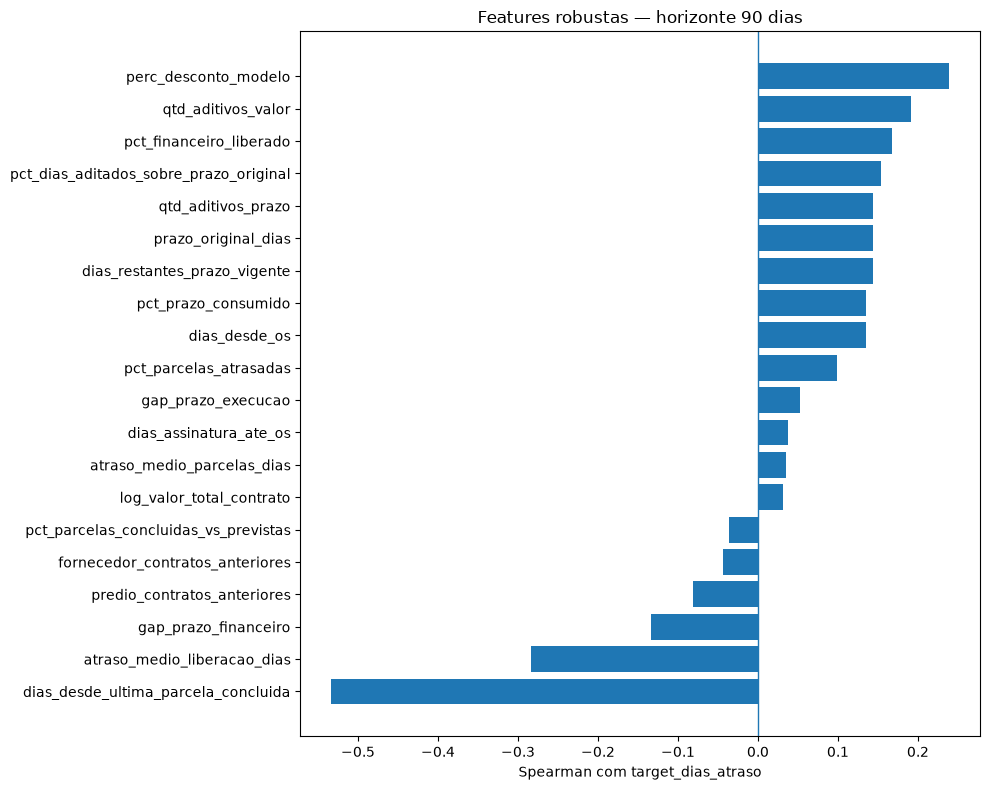

In [5]:
base90=snapshot_horizonte(base,90)
ranking90=(corr_num(base90).merge(mi_num(base90),on="feature",how="left")
           .sort_values(["abs_spearman","mutual_information"],ascending=False))
print("Contratos cobertos:", base90["id_contrato"].nunique())
display(ranking90.round(4))

p=ranking90.sort_values("spearman")
plt.figure(figsize=(10,8))
plt.barh(p["feature"],p["spearman"])
plt.axvline(0,linewidth=1)
plt.xlabel("Spearman com target_dias_atraso")
plt.title("Features robustas — horizonte 90 dias")
plt.tight_layout()
plt.show()

## Estabilidade por horizonte
Uma feature é mais confiável quando sua associação não muda radicalmente de direção entre os horizontes.

In [6]:
HORIZONTES=[180,90,60,30]
partes=[]
for h in HORIZONTES:
    bh=snapshot_horizonte(base,h)
    t=corr_num(bh)[["feature","spearman","n"]]
    t["horizonte"]=h
    t["contratos"]=bh["id_contrato"].nunique()
    partes.append(t)
corr_h=pd.concat(partes,ignore_index=True)

est=corr_h.pivot(index="feature",columns="horizonte",values="spearman").reindex(columns=HORIZONTES)
est.columns=[f"spearman_{h}d" for h in HORIZONTES]
est["spearman_medio_abs"]=est.abs().mean(axis=1)
est["desvio_spearman"]=est.std(axis=1)

def consistente(row):
    v=row[[c for c in row.index if c.startswith("spearman_") and c.endswith("d")]].dropna().values
    v=v[np.abs(v)>=.05]
    return np.nan if len(v)<=1 else bool(np.all(v>0) or np.all(v<0))
est["sinal_consistente"]=est.apply(consistente,axis=1)
display(est.sort_values("spearman_medio_abs",ascending=False).round(4))

,spearman_180d,spearman_90d,spearman_60d,spearman_30d,spearman_medio_abs,desvio_spearman,sinal_consistente
feature,,,,,,,
dias_desde_ultima_parcela_concluida,-0.3028,-0.5333,0.0657,0.1709,0.2682,0.3390,False
pct_parcelas_concluidas_vs_previstas,-0.3753,-0.0361,0.0677,-0.3250,0.2010,0.2495,False
qtd_aditivos_valor,-0.2027,0.1912,0.1661,0.0999,0.1650,0.1637,False
atraso_medio_liberacao_dias,-0.0947,-0.2832,-0.1705,-0.0890,0.1594,0.1627,True
gap_prazo_execucao,0.2277,0.0520,-0.0302,0.3175,0.1568,0.1379,True
pct_parcelas_atrasadas,-0.0866,0.0989,0.1329,0.2108,0.1323,0.1109,False
perc_desconto_modelo,NaN,0.2390,0.0624,0.0624,0.1212,0.0832,True
gap_prazo_financeiro,-0.0928,-0.1343,-0.0687,0.1746,0.1176,0.1375,False
pct_dias_aditados_sobre_prazo_original,-0.0240,0.1533,0.1003,-0.1416,0.1048,0.1201,False


## Redundância entre features
Pares com |Spearman| ≥ 0,80 merecem revisão para evitar informação duplicada.

In [7]:
cf=base90[NUMERIC_FEATURES].corr(method="spearman")
pares=[]
for i,a in enumerate(cf.columns):
    for b in cf.columns[i+1:]:
        r=cf.loc[a,b]
        if pd.notna(r):
            pares.append({"feature_1":a,"feature_2":b,"spearman_entre_features":r,"abs_spearman":abs(r)})
redund=pd.DataFrame(pares).sort_values("abs_spearman",ascending=False)
display(redund.head(30).round(4))
print("Pares >= 0.80:")
display(redund[redund["abs_spearman"].ge(.80)].round(4))

,feature_1,feature_2,spearman_entre_features,abs_spearman
99,dias_desde_os,pct_prazo_consumido,1.0000,1.0000
134,qtd_aditivos_prazo,pct_dias_aditados_sobre_prazo_original,0.9946,0.9946
5,prazo_original_dias,dias_desde_os,0.9919,0.9919
7,prazo_original_dias,pct_prazo_consumido,0.9919,0.9919
47,perc_desconto_modelo,pct_parcelas_atrasadas,0.9636,0.9636
107,dias_desde_os,pct_financeiro_liberado,0.9396,0.9396
130,pct_prazo_consumido,pct_financeiro_liberado,0.9396,0.9396
15,prazo_original_dias,pct_financeiro_liberado,0.9352,0.9352
135,qtd_aditivos_prazo,qtd_aditivos_valor,0.7595,0.7595
144,pct_dias_aditados_sobre_prazo_original,qtd_aditivos_valor,0.7540,0.7540


Pares >= 0.80:


,feature_1,feature_2,spearman_entre_features,abs_spearman
99,dias_desde_os,pct_prazo_consumido,1.0000,1.0000
134,qtd_aditivos_prazo,pct_dias_aditados_sobre_prazo_original,0.9946,0.9946
5,prazo_original_dias,dias_desde_os,0.9919,0.9919
7,prazo_original_dias,pct_prazo_consumido,0.9919,0.9919
47,perc_desconto_modelo,pct_parcelas_atrasadas,0.9636,0.9636
107,dias_desde_os,pct_financeiro_liberado,0.9396,0.9396
130,pct_prazo_consumido,pct_financeiro_liberado,0.9396,0.9396
15,prazo_original_dias,pct_financeiro_liberado,0.9352,0.9352


## Features categóricas
Não tratamos os códigos categóricos como números para calcular Pearson/Spearman. Mostramos a distribuição do target por categoria.

In [8]:
for f in CATEGORICAL_FEATURES:
    print("\n==",f,"==")
    r=(base90.groupby(f,dropna=False)[TARGET]
       .agg(contratos="count",media="mean",mediana="median",minimo="min",maximo="max")
       .sort_values(["contratos","media"],ascending=[False,False]))
    display(r.round(2))


== classificacao_contrato ==


,contratos,media,mediana,minimo,maximo
classificacao_contrato,,,,,
Reforma Parcial,25,28.92,0.0,0.0,281.0
Reforma Parcial e Ampliação,4,39.00,25.0,0.0,106.0
Construção,4,18.75,0.0,0.0,75.0



== id_setor_divisao ==


,contratos,media,mediana,minimo,maximo
id_setor_divisao,,,,,
10,28,31.54,0.0,0.0,281.0
12,3,4.67,0.0,0.0,14.0
8,1,40.00,40.0,40.0,40.0
32,1,17.00,17.0,17.0,17.0


## Comparação: todos os snapshots vs. 90 dias
Todos os snapshots são úteis como diagnóstico, mas não são observações independentes.

In [9]:
allcorr=corr_num(base)[["feature","pearson","spearman"]].rename(
    columns={"pearson":"pearson_todos_snapshots","spearman":"spearman_todos_snapshots"})
comp=ranking90[["feature","pearson","spearman","mutual_information"]].merge(allcorr,on="feature")
display(comp.round(4))

,feature,pearson,spearman,mutual_information,pearson_todos_snapshots,spearman_todos_snapshots
0,dias_desde_ultima_parcela_concluida,-0.2739,-0.5333,0.0007,0.4426,0.1875
1,atraso_medio_liberacao_dias,-0.2382,-0.2832,0.0502,0.0299,-0.0240
2,perc_desconto_modelo,0.3175,0.2390,0.0826,0.7044,0.4547
3,qtd_aditivos_valor,-0.0164,0.1912,0.0000,-0.0076,0.1172
4,pct_financeiro_liberado,0.3032,0.1678,0.0000,0.3626,0.2531
5,pct_dias_aditados_sobre_prazo_original,0.0689,0.1533,0.0000,0.0945,0.0816
6,qtd_aditivos_prazo,0.0890,0.1442,0.0000,0.2300,0.1091
7,prazo_original_dias,0.1999,0.1437,0.0597,-0.0299,0.0062
8,dias_restantes_prazo_vigente,0.0317,0.1437,0.0000,-0.2830,-0.2384
9,dias_desde_os,0.1764,0.1350,0.0477,0.2497,0.1881


## Triagem final
`REVISAR` significa apenas baixo sinal univariado no horizonte de 90 dias **e** baixa informação mútua. Não significa excluir automaticamente.

In [10]:
triagem=ranking90.merge(est.reset_index(),on="feature",how="left")
triagem["redundancia_max"]=triagem["feature"].map(
    lambda f: redund.loc[(redund["feature_1"].eq(f))|(redund["feature_2"].eq(f)),"abs_spearman"].max())
triagem["baixo_sinal_90d"]=triagem["abs_spearman"].fillna(0).lt(.10)
triagem["baixa_mi"]=triagem["mutual_information"].fillna(0).lt(.02)
triagem["muito_redundante"]=triagem["redundancia_max"].fillna(0).ge(.80)
triagem["triagem"]=np.where(triagem["baixo_sinal_90d"] & triagem["baixa_mi"],
                            "REVISAR","MANTER/INVESTIGAR")
cols=["feature","spearman","pearson","mutual_information","spearman_medio_abs",
      "desvio_spearman","sinal_consistente","redundancia_max","pct_missing",
      "muito_redundante","triagem"]
display(triagem[cols].sort_values(["triagem","spearman_medio_abs"],
                                  ascending=[False,False]).round(4))

,feature,spearman,pearson,mutual_information,spearman_medio_abs,desvio_spearman,sinal_consistente,redundancia_max,pct_missing,muito_redundante,triagem
17,pct_parcelas_concluidas_vs_previstas,-0.0361,0.0262,0.0000,0.2010,0.2495,False,0.6616,0.3939,False,REVISAR
15,fornecedor_contratos_anteriores,-0.0434,0.0949,0.0000,0.0942,0.1107,True,0.5191,0.0000,False,REVISAR
13,predio_contratos_anteriores,-0.0810,-0.0917,0.0000,0.0846,0.0910,True,0.6742,0.0000,False,REVISAR
18,atraso_medio_parcelas_dias,0.0353,0.1329,0.0000,0.0802,0.0854,True,0.6904,0.3636,False,REVISAR
16,dias_assinatura_ate_os,0.0375,0.5138,0.0000,0.0675,0.0870,NaN,0.5191,0.0000,False,REVISAR
19,log_valor_total_contrato,0.0310,0.0433,0.0000,0.0362,0.0467,NaN,0.7341,0.0000,False,REVISAR
0,dias_desde_ultima_parcela_concluida,-0.5333,-0.2739,0.0007,0.2682,0.3390,False,0.4540,0.3636,False,MANTER/INVESTIGAR
3,qtd_aditivos_valor,0.1912,-0.0164,0.0000,0.1650,0.1637,False,0.7595,0.0000,False,MANTER/INVESTIGAR
1,atraso_medio_liberacao_dias,-0.2832,-0.2382,0.0502,0.1594,0.1627,True,0.5445,0.4242,False,MANTER/INVESTIGAR
14,gap_prazo_execucao,0.0520,0.1756,0.1457,0.1568,0.1379,True,0.7163,0.3939,False,MANTER/INVESTIGAR


In [11]:
OUTPUT_DIR=Path("/mnt/data/05_analise_correlacao_outputs")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
ranking90.to_csv(OUTPUT_DIR/"05_ranking_correlacao_90d.csv",index=False,encoding="utf-8-sig")
corr_h.to_csv(OUTPUT_DIR/"05_correlacao_por_horizonte.csv",index=False,encoding="utf-8-sig")
redund.to_csv(OUTPUT_DIR/"05_redundancia_features.csv",index=False,encoding="utf-8-sig")
triagem.to_csv(OUTPUT_DIR/"05_triagem_features.csv",index=False,encoding="utf-8-sig")
print("Resultados:",OUTPUT_DIR)

Resultados: \mnt\data\05_analise_correlacao_outputs


## Interpretação recomendada
Não elimine uma variável apenas por correlação baixa. Priorize candidatas que combinem: baixo Spearman, baixa informação mútua, instabilidade entre horizontes, forte redundância e/ou pouca justificativa operacional. Depois, confirme qualquer redução repetindo a validação temporal do notebook 04.